# Machine Learning Project: Hospital Readmission Prediction

## 1. Problem Framing
* **Stakeholder:** Hospital Care-Planning Team and Administrators.
* **Decision Need:** Identifying which diabetic patients require immediate extra follow-up care and resource allocation after discharge to prevent early readmission.
* **Primary Lens:** 30-day hospital readmission risk prediction.
* **Secondary Lens:** High-risk patient profiling (identifying common characteristics and risk drivers).
* **Unit of Analysis:** One single hospital encounter (visit) by a diabetic patient.
* **Exact Task/Output:** Supervised Binary Classification to predict early hospital readmission risk:
  * **Positive Class (1):** Patient readmitted within 30 days (`<30`)
  * **Negative Class (0):** Patient not readmitted within 30 days (`NO` or `>30` combined)
* **Rationale:** Aligns directly with the clinical decision need and the US Centers for Medicare & Medicaid Services (CMS) Hospital Readmissions Reduction Program (HRRP). Hospitals are evaluated and penalized specifically on 30-day bounce-backs; distinguishing between late readmission (>30 days) and no readmission is clinically irrelevant for acute transitional discharge planning.



## Exploratory Data Analysis (EDA)
This notebook performs a comprehensive EDA following the project requirements. We apply analysis across ALL features to ensure no potential signal is missed.



In [1]:
import os
import sys
import math
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

# Working directory and directory resolution
if not os.path.exists('dataset_extracted') and os.path.exists('../dataset_extracted'):
    os.chdir('..')

data_dir = 'dataset_extracted' if os.path.exists('dataset_extracted') else '../dataset_extracted'
plots_dir = 'plots' if os.path.exists('plots') else 'eda/plots'

warnings.filterwarnings('ignore')
%matplotlib inline
sns.set_theme(style="whitegrid")

os.makedirs(f'{plots_dir}/EDA', exist_ok=True)


## 1. Dataset Overview
We begin by loading the dataset, checking its shape, data types, and identifying the key identifier columns vs features.


In [2]:
# keep_default_na=False -> text "None" is NOT turned into NaN. IDs stay integers.
df = pd.read_csv(f'{data_dir}/diabetic_data.csv', keep_default_na=False)

# Parse IDS_mapping.csv (3 tables stacked, blank-row separated)
with open(f'{data_dir}/IDS_mapping.csv', 'r') as f:
    lines = f.readlines()

mapping_dicts, current_map = {}, None
for line in lines:
    line = line.strip()
    if not line or line.strip(',') == '':          # skip blank and ",," separator rows
        continue
    if line.endswith('_id,description'):
        current_map = line.split(',')[0]
        mapping_dicts[current_map] = {}
    elif current_map:
        key, val = line.split(',', 1)
        mapping_dicts[current_map][int(key)] = val.strip().strip('"')   # int keys

# Readable *_desc columns (original numeric codes stay unchanged)
code_cols = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
desc_cols = []
for c in code_cols:
    new = c.replace('_id', '_desc')
    # Map the integers, but if the dictionary doesn't have the integer, fill the resulting NaN with 'Unknown/Unmapped'
    df[new] = df[c].map(mapping_dicts[c]).fillna('Unknown/Unmapped')
    desc_cols.append(new)

print(f"Unmapped codes (now filled with 'Unknown/Unmapped'): {(df[desc_cols] == 'Unknown/Unmapped').sum().to_dict()}")
print(f"Dataset Shape: {df.shape}")
print("\nMemory Usage:")
df.info(memory_usage='deep')

# Separate columns by type
id_cols = ['encounter_id', 'patient_nbr']
target_col = 'readmitted'
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
numeric_cols = df.select_dtypes(exclude=['object']).columns.tolist()

categorical_cols = [c for c in categorical_cols if c not in id_cols + [target_col] + desc_cols]
numeric_cols = [c for c in numeric_cols if c not in id_cols + [target_col] + code_cols]
categorical_cols += code_cols          # codes are categories, not quantities

print(f"\nIdentifier Columns: {id_cols}")
print(f"Target Column: {target_col}")
print(f"Numerical Columns ({len(numeric_cols)}): {numeric_cols}")
print(f"Categorical Columns ({len(categorical_cols)}): {categorical_cols}")

# Basic first look
print("\n--- Head ---");  display(df.head())
print("\n--- Tail ---");  display(df.tail())
print("\n--- Numeric Describe ---");     display(df[numeric_cols].describe().T)
print("\n--- Categorical Describe ---");  display(df[categorical_cols].describe().T)
print("\n--- Nunique ---");  display(df.nunique().sort_values())



Unmapped codes (now filled with 'Unknown/Unmapped'): {'admission_type_desc': 0, 'discharge_disposition_desc': 0, 'admission_source_desc': 0}
Dataset Shape: (101766, 53)

Memory Usage:


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 53 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   encounter_id                101766 non-null  int64 
 1   patient_nbr                 101766 non-null  int64 
 2   race                        101766 non-null  object
 3   gender                      101766 non-null  object
 4   age                         101766 non-null  object
 5   weight                      101766 non-null  object
 6   admission_type_id           101766 non-null  int64 
 7   discharge_disposition_id    101766 non-null  int64 
 8   admission_source_id         101766 non-null  int64 
 9   time_in_hospital            101766 non-null  int64 
 10  payer_code                  101766 non-null  object
 11  medical_specialty           101766 non-null  object
 12  num_lab_procedures          101766 non-null  int64 
 13  num_procedures              1

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,admission_type_desc,discharge_disposition_desc,admission_source_desc
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,NO,NULL,Not Mapped,Physician Referral
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,No,No,No,Ch,Yes,>30,Emergency,Discharged to home,Emergency Room
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,Yes,NO,Emergency,Discharged to home,Emergency Room
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,No,No,No,Ch,Yes,NO,Emergency,Discharged to home,Emergency Room
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,No,No,No,Ch,Yes,NO,Emergency,Discharged to home,Emergency Room



--- Tail ---


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted,admission_type_desc,discharge_disposition_desc,admission_source_desc
101761,443847548,100162476,AfricanAmerican,Male,[70-80),?,1,3,7,3,...,No,No,No,No,Ch,Yes,>30,Emergency,Discharged/transferred to SNF,Emergency Room
101762,443847782,74694222,AfricanAmerican,Female,[80-90),?,1,4,5,5,...,No,No,No,No,No,Yes,NO,Emergency,Discharged/transferred to ICF,Transfer from a Skilled Nursing Facility (SNF)
101763,443854148,41088789,Caucasian,Male,[70-80),?,1,1,7,1,...,No,No,No,No,Ch,Yes,NO,Emergency,Discharged to home,Emergency Room
101764,443857166,31693671,Caucasian,Female,[80-90),?,2,3,7,10,...,No,No,No,No,Ch,Yes,NO,Urgent,Discharged/transferred to SNF,Emergency Room
101765,443867222,175429310,Caucasian,Male,[70-80),?,1,1,7,6,...,No,No,No,No,No,No,NO,Emergency,Discharged to home,Emergency Room


...

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,101766.0,4.395987,2.985108,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,101766.0,43.095641,19.674362,1.0,31.0,44.0,57.0,132.0
num_procedures,101766.0,1.339730,1.705807,0.0,0.0,1.0,2.0,6.0
num_medications,101766.0,16.021844,8.127566,1.0,10.0,15.0,20.0,81.0
number_outpatient,101766.0,0.369357,1.267265,0.0,0.0,0.0,0.0,42.0
number_emergency,101766.0,0.197836,0.930472,0.0,0.0,0.0,0.0,76.0
number_inpatient,101766.0,0.635566,1.262863,0.0,0.0,0.0,1.0,21.0
number_diagnoses,101766.0,7.422607,1.933600,1.0,6.0,8.0,9.0,16.0



--- Categorical Describe ---


,count,mean,std,min,25%,50%,75%,max
admission_type_id,101766.0,2.024006,1.445403,1.0,1.0,1.0,3.0,8.0
discharge_disposition_id,101766.0,3.715642,5.280166,1.0,1.0,1.0,4.0,28.0
admission_source_id,101766.0,5.754437,4.064081,1.0,1.0,7.0,7.0,25.0



--- Nunique ---


citoglipton                        1
examide                            1
acetohexamide                      2
glipizide-metformin                2
tolbutamide                        2
troglitazone                       2
metformin-rosiglitazone            2
glimepiride-pioglitazone           2
metformin-pioglitazone             2
change                             2
diabetesMed                        2
gender                             3
tolazamide                         3
readmitted                         3
nateglinide                        4
metformin                          4
acarbose                           4
rosiglitazone                      4
pioglitazone                       4
miglitol                           4
A1Cresult                          4
glimepiride                        4
glyburide                          4
repaglinide                        4
chlorpropamide                     4
glipizide                          4
max_glu_serum                      4
i

### What we learned
- The dataset has 101,766 rows and 50 columns.
- `encounter_id` and `patient_nbr` are identifiers, and `readmitted` is the target.
- Most features are stored as `object` (categorical/strings), and there are several numerical features.
- Missing values are coded as `?` instead of actual NaNs.

### What we will do about it
- We will convert the `?` placeholders into proper `NaN` values.
- We will dynamically loop through all identified numerical and categorical columns for comprehensive EDA rather than selectively picking a few.



## 2. Target Analysis
The raw target in the hospital records is `readmitted` with 3 categorical outcomes: `NO`, `>30`, and `<30`.
For acute transitional care triage (CMS HRRP operational guidelines), our primary objective is **Binary Classification**:
* **Positive Class (1):** Early Readmission within 30 days (`<30`)
* **Negative Class (0):** Not Readmitted within 30 days (`NO` or `>30` combined)

We inspect both the raw 3-class breakdown and the operational binary distribution side-by-side.


=== Raw 3-Class Target Distribution ===
        Count  Percentage (%)
target                       
NO      54864       53.911916
>30     35545       34.928169
<30     11357       11.159916



=== Operational Binary Target Distribution ===
                     Count  Percentage (%)
target_binary                             
Negative (NO / >30)  90409       88.840084
Positive (<30)       11357       11.159916


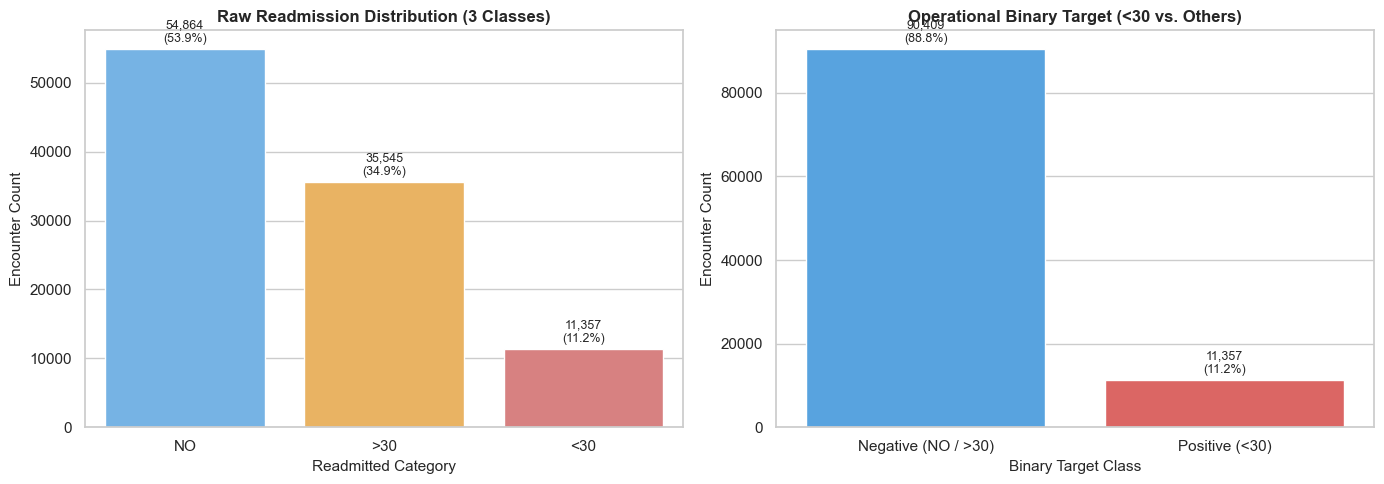

In [3]:
# 3-Class raw target
df['target'] = df['readmitted']
counts_3class = df['target'].value_counts()
pcts_3class = df['target'].value_counts(normalize=True) * 100
target_stats_3class = pd.DataFrame({'Count': counts_3class, 'Percentage (%)': pcts_3class})
print("=== Raw 3-Class Target Distribution ===")
print(target_stats_3class)

# Operational Binary Target: 1 (<30) vs 0 (NO or >30)
df['target_binary'] = (df['readmitted'] == '<30').astype(int)
binary_counts = df['target_binary'].value_counts().rename({0: 'Negative (NO / >30)', 1: 'Positive (<30)'})
binary_pcts = (df['target_binary'].value_counts(normalize=True) * 100).rename({0: 'Negative (NO / >30)', 1: 'Positive (<30)'})
target_stats_binary = pd.DataFrame({'Count': binary_counts, 'Percentage (%)': binary_pcts})
print("\n=== Operational Binary Target Distribution ===")
print(target_stats_binary)

# Side-by-side visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Raw 3-Class Distribution
ax1 = sns.barplot(x=counts_3class.index, y=counts_3class.values, ax=axes[0], order=['NO', '>30', '<30'], palette=['#64b5f6', '#ffb74d', '#e57373'])
axes[0].set_title('Raw Readmission Distribution (3 Classes)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Readmitted Category', fontsize=11)
axes[0].set_ylabel('Encounter Count', fontsize=11)
for p in ax1.patches:
    height = int(p.get_height())
    pct = (height / len(df)) * 100
    ax1.annotate(f'{height:,}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2., height),
                 ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

# Plot 2: Operational Binary Target Distribution
ax2 = sns.barplot(x=binary_counts.index, y=binary_counts.values, ax=axes[1], palette=['#42a5f5', '#ef5350'])
axes[1].set_title('Operational Binary Target (<30 vs. Others)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Binary Target Class', fontsize=11)
axes[1].set_ylabel('Encounter Count', fontsize=11)
for p in ax2.patches:
    height = int(p.get_height())
    pct = (height / len(df)) * 100
    ax2.annotate(f'{height:,}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2., height),
                 ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.savefig(f'{plots_dir}/EDA/target_distribution.png', bbox_inches='tight')
plt.show()



### What we learned from Target Analysis
- **Raw 3-Class Breakdown:** `NO` constitutes ~53.9% (54,864), `>30` constitutes ~34.9% (35,545), and `<30` constitutes ~11.2% (11,357).
- **Operational Binary Target:** When formulated for acute 30-day transitional care (`<30` vs `NO` + `>30`), the positive class (`<30`) is **~11.2% (11,357)** and the negative class is **~88.8% (90,409)**.
- **Severe Class Imbalance:** Because early readmission is a minority occurrence (~11.2%), raw accuracy will be misleading (predicting all 0s yields ~88.8% accuracy while failing 100% of high-risk patients).

### What we will do about it
- Formulate model evaluation around **Recall**, **Positive F1-Score**, and **PR-AUC / ROC-AUC**.
- Employ patient-level stratification (`patient_nbr`) and address imbalance via algorithmic loss weighting (`class_weight='balanced'`) and optional training-only resampling (SMOTE / RandomOverSampler).



## 3. Missing Values
We replace all string placeholders with NaN and calculate missingness across ALL columns.


                            Missing_Count  Missing_Pct
weight                              98569    96.858479
medical_specialty                   49949    49.082208
payer_code                          40256    39.557416
admission_type_desc                 10396    10.215593
admission_source_desc                7067     6.944363
discharge_disposition_desc           4680     4.598785
race                                 2273     2.233555
diag_3                               1423     1.398306
diag_2                                358     0.351787
diag_1                                 21     0.020636
gender                                  3     0.002948


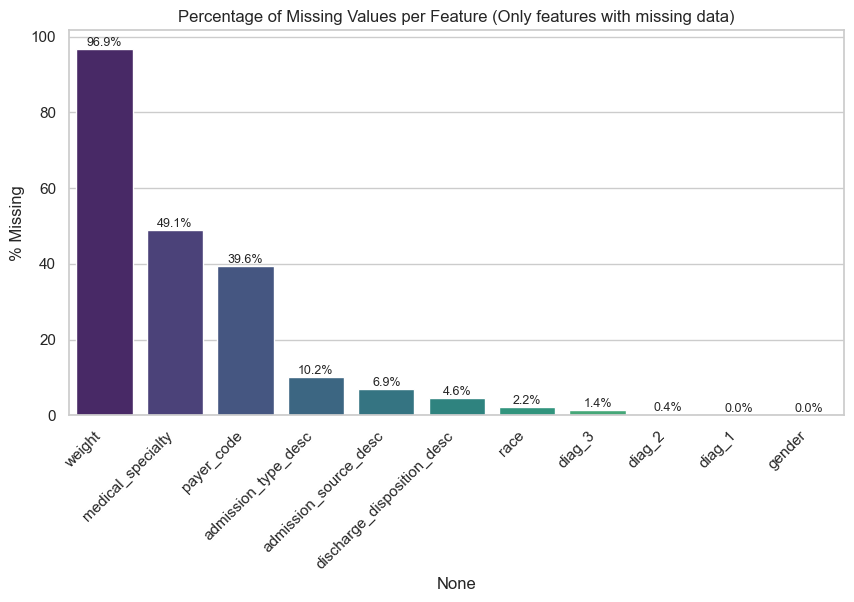

In [4]:
# Replace placeholders with NaN
placeholders = ['?', 'Unknown/Invalid', 'Not Available', 'NULL', 'Not Mapped']
df.replace(placeholders, np.nan, inplace=True)

# Calculate missing percentages for all features
missing_counts = df.isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({'Missing_Count': missing_counts, 'Missing_Pct': missing_pct})
missing_df = missing_df[missing_df['Missing_Pct'] > 0].sort_values(by='Missing_Pct', ascending=False)

print(missing_df)

# Plot
plt.figure(figsize=(10, 5))
if not missing_df.empty:
    ax = sns.barplot(x=missing_df.index, y='Missing_Pct', data=missing_df, palette='viridis')
    for c in ax.containers: ax.bar_label(c, fmt='%.1f%%', fontsize=9)
    plt.xticks(rotation=45, ha='right')
    plt.title('Percentage of Missing Values per Feature (Only features with missing data)')
    plt.ylabel('% Missing')
    plt.savefig(f'{plots_dir}/EDA/missing_values.png', bbox_inches='tight')
    plt.show()
else:
    print("No missing values found after processing!")



### What we learned
- `weight` is missing in ~97% of the records.
- `medical_specialty` is missing ~49%.
- `payer_code` is missing ~39%.
- `race` and a few others have <5% missing values.

### What we will do about it
- **Drop** `weight` entirely due to excessive missingness.
- For `medical_specialty` and `payer_code`, we will fill with an `"Unknown"` category because the fact that it is missing might itself carry predictive information (e.g., lack of specialist access).
- For low-missingness columns like `race`, we will impute with the mode (most frequent) or drop those specific rows.



## 4. Duplicates & Patient Leakage Risk
Checking for identical rows and repeated encounters for the same patient.


Exact duplicate rows: 0
Unique patients: 71518 across 101766 total encounters.
Max encounters for a single patient: 40


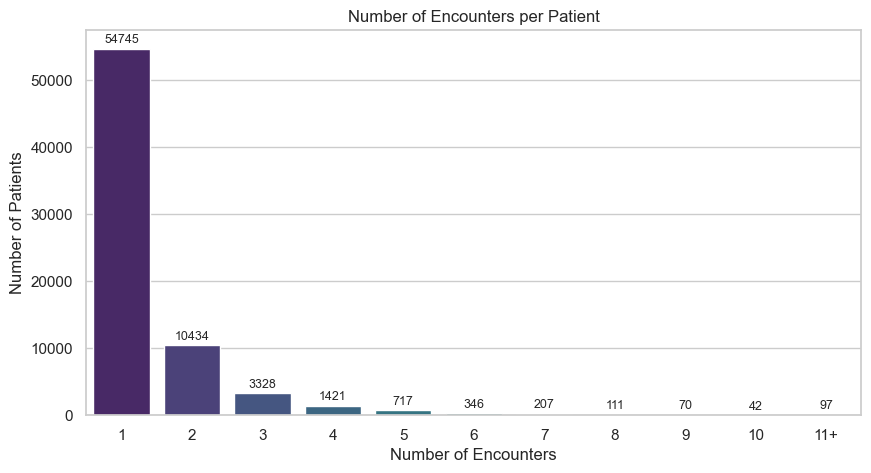

In [5]:
# Exact duplicate rows
print(f"Exact duplicate rows: {df.duplicated().sum()}")

# Patient encounters distribution
unique_patients = df['patient_nbr'].nunique()
print(f"Unique patients: {unique_patients} across {len(df)} total encounters.")

encounter_counts = df['patient_nbr'].value_counts()
print(f"Max encounters for a single patient: {encounter_counts.max()}")

# Group encounters into 1, 2, ..., 10, 11+
grouped_encounters = encounter_counts.apply(lambda x: str(x) if x <= 10 else '11+')
order = [str(i) for i in range(1, 11)] + ['11+']
grouped_counts = grouped_encounters.value_counts().reindex(order).fillna(0)

plt.figure(figsize=(10, 5))
ax = sns.barplot(x=grouped_counts.index, y=grouped_counts.values, palette='viridis')
plt.title('Number of Encounters per Patient')
plt.xlabel('Number of Encounters')
plt.ylabel('Number of Patients')

# Annotate counts above bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='baseline', fontsize=9, xytext=(0, 4), textcoords='offset points')

plt.savefig(f'{plots_dir}/EDA/encounters_per_patient.png', bbox_inches='tight')
plt.show()



### What we learned
- There are no exact duplicate rows.
- However, there are ~71,518 unique patients for ~101,766 encounters, meaning tens of thousands of patients visit multiple times (up to 40 times!).

### What we will do about it
- We **must split the train/test sets by `patient_nbr`**, not randomly. Random splitting would cause data leakage. 
- We will likely extract only the first encounter per patient during preprocessing, or use GroupKFold.



## 5. Univariate Analysis
Let's explore the distribution of **ALL** numerical and categorical variables dynamically. We will plot every feature.


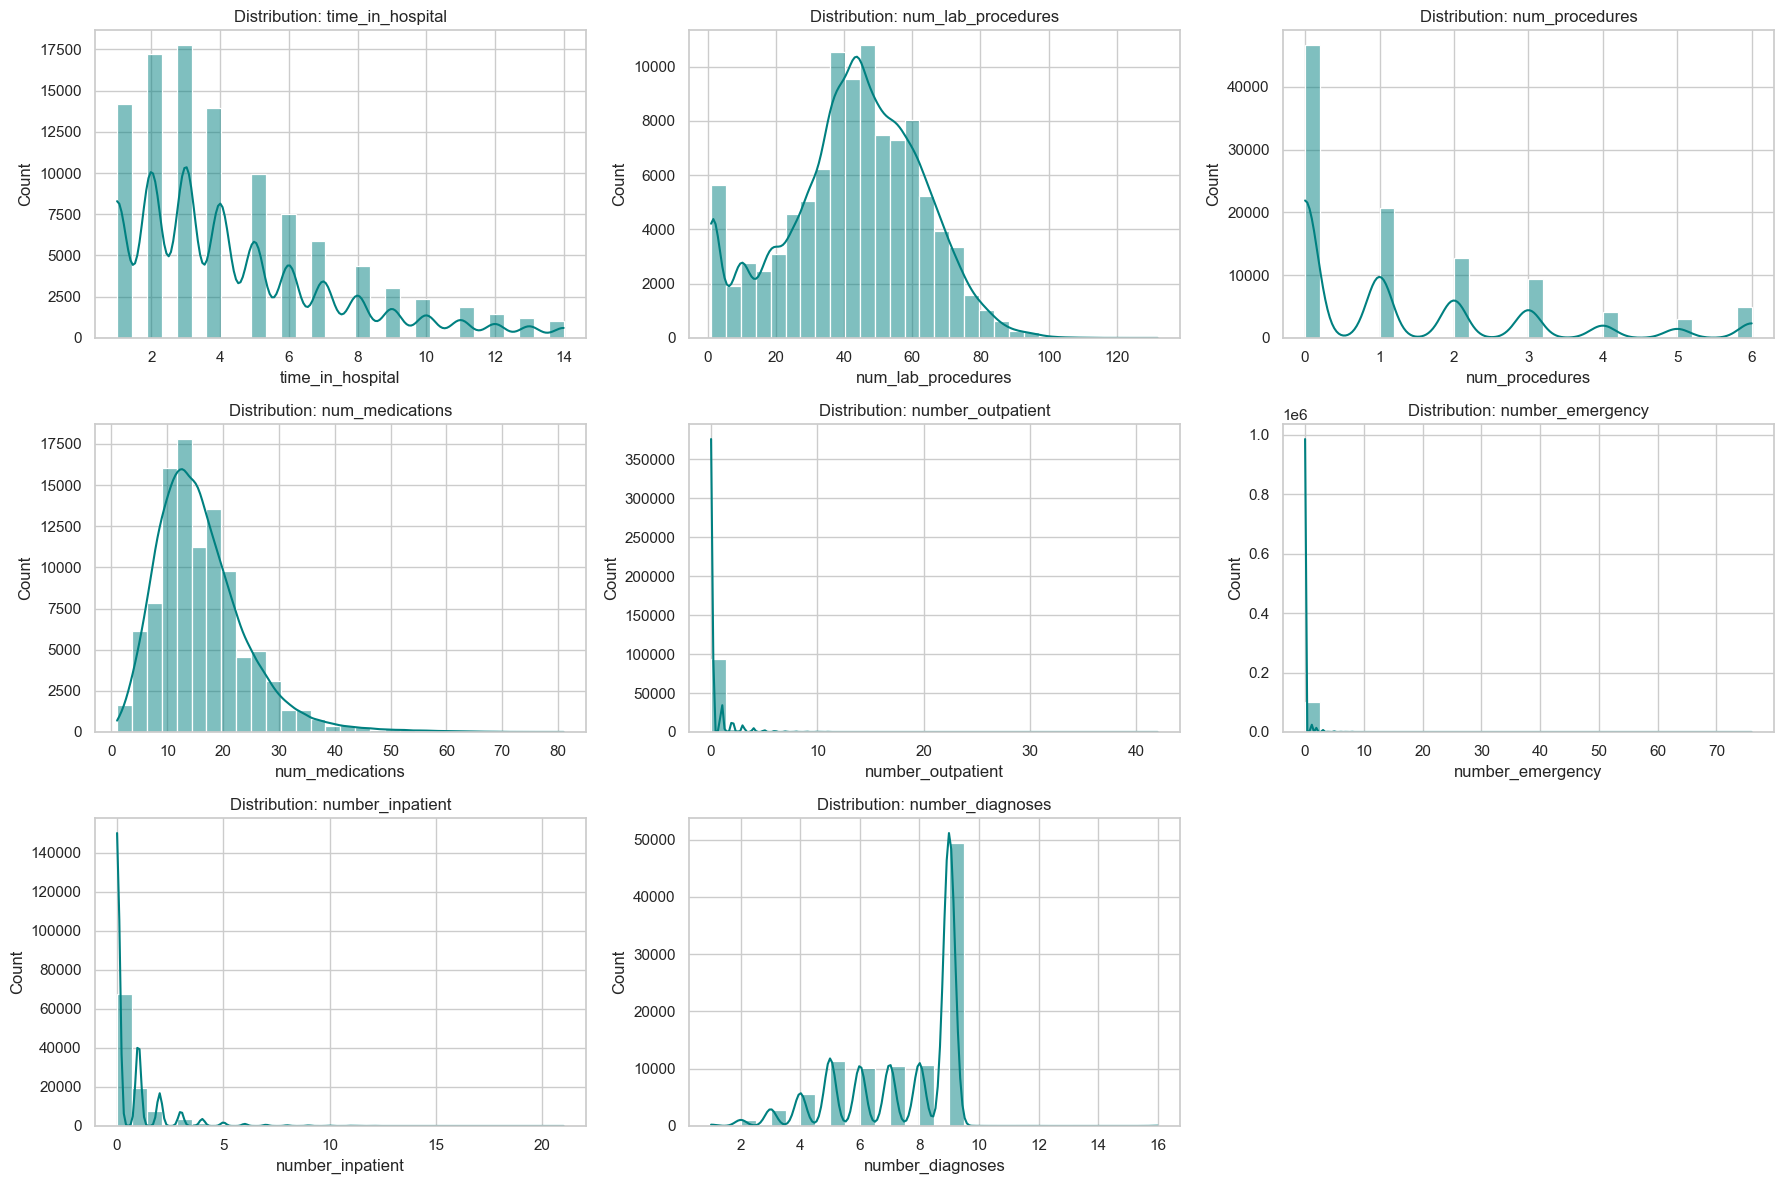


Numerical Statistics & Outliers:
                       count       mean        std  min   25%   50%   75%  \
time_in_hospital    101766.0   4.395987   2.985108  1.0   2.0   4.0   6.0   
num_lab_procedures  101766.0  43.095641  19.674362  1.0  31.0  44.0  57.0   
num_procedures      101766.0   1.339730   1.705807  0.0   0.0   1.0   2.0   
num_medications     101766.0  16.021844   8.127566  1.0  10.0  15.0  20.0   
number_outpatient   101766.0   0.369357   1.267265  0.0   0.0   0.0   0.0   
number_emergency    101766.0   0.197836   0.930472  0.0   0.0   0.0   0.0   
number_inpatient    101766.0   0.635566   1.262863  0.0   0.0   0.0   1.0   
number_diagnoses    101766.0   7.422607   1.933600  1.0   6.0   8.0   9.0   

                      max   skewness  outliers (IQR)  
time_in_hospital     14.0   1.133999            2252  
num_lab_procedures  132.0  -0.236544             143  
num_procedures        6.0   1.316415            4954  
num_medications      81.0   1.326672            2557

In [6]:
# Plot ALL Numerical features
num_cols_count = len(numeric_cols)
rows = math.ceil(num_cols_count / 3)
fig, axes = plt.subplots(rows, 3, figsize=(18, rows * 4))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(df[col], kde=True, ax=axes[i], color='teal', bins=30)
    axes[i].set_title(f'Distribution: {col}')

# Hide any empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(f'{plots_dir}/EDA/univariate_numerical.png', bbox_inches='tight')
plt.show()

# Stats
stats_df = df[numeric_cols].describe().T
stats_df['skewness'] = df[numeric_cols].skew()

# IQR Outlier Detection
outliers_list = []
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers_count = ((df[col] < lower) | (df[col] > upper)).sum()
    outliers_list.append(outliers_count)
    
stats_df['outliers (IQR)'] = outliers_list
print("\nNumerical Statistics & Outliers:")
print(stats_df)



### Outlier Visualization (Boxplots)
To visually inspect the outliers detected by the IQR method above, we plot boxplots for all numerical features.


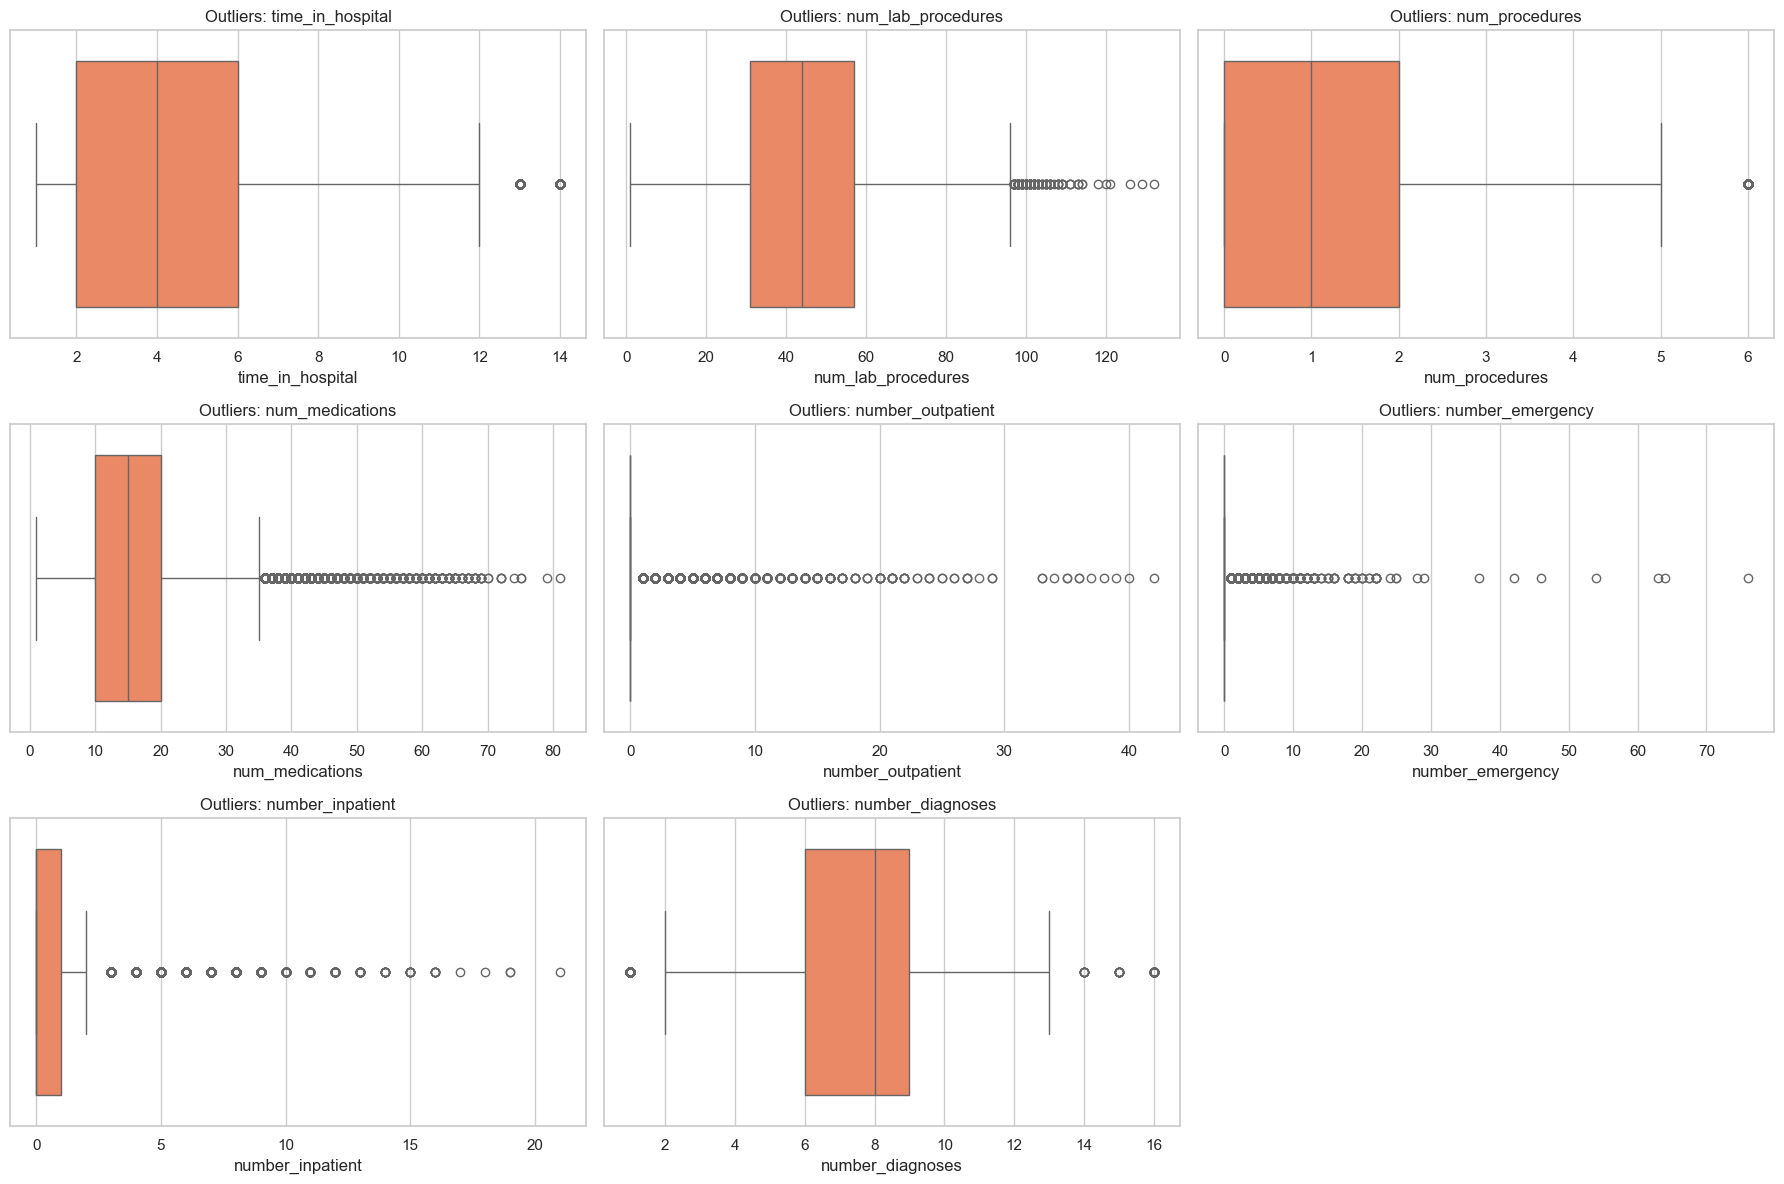

In [7]:
# Boxplots for numerical outliers
fig, axes = plt.subplots(rows, 3, figsize=(18, rows * 4))
axes = axes.flatten()

num_tables = {}
for i, col in enumerate(numeric_cols):
    sns.boxplot(x=df[col], ax=axes[i], color='coral')
    axes[i].set_title(f'Outliers: {col}')

# Hide any empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(f'{plots_dir}/EDA/outliers_boxplots.png', bbox_inches='tight')
plt.show()



### What we learned (Numerical Distributions & Outliers)
- Most numerical features, particularly count-based variables like `number_inpatient`, `number_emergency`, and `number_outpatient`, are heavily right-skewed and zero-inflated.
- The boxplots reveal severe right-tail outliers across almost all numerical features. This reflects that a small subset of "high-utilizer" patients have extremely high historical hospital usage.
- `time_in_hospital` and `num_lab_procedures` follow more normalized, albeit slightly skewed, distributions.

### What we will do about it
- We will NOT simply drop these outliers, as these extreme "high-utilizer" patients carry highly valuable predictive signals for readmission.
- Instead, due to the extreme right-skew and heavy presence of zeros, we will apply a `log1p` (`log(1 + x)`) transformation to these features during preprocessing.
- `log1p` safely compresses the extreme outlier tails and handles the zeros gracefully, which will significantly stabilize linear models without losing the underlying signal.



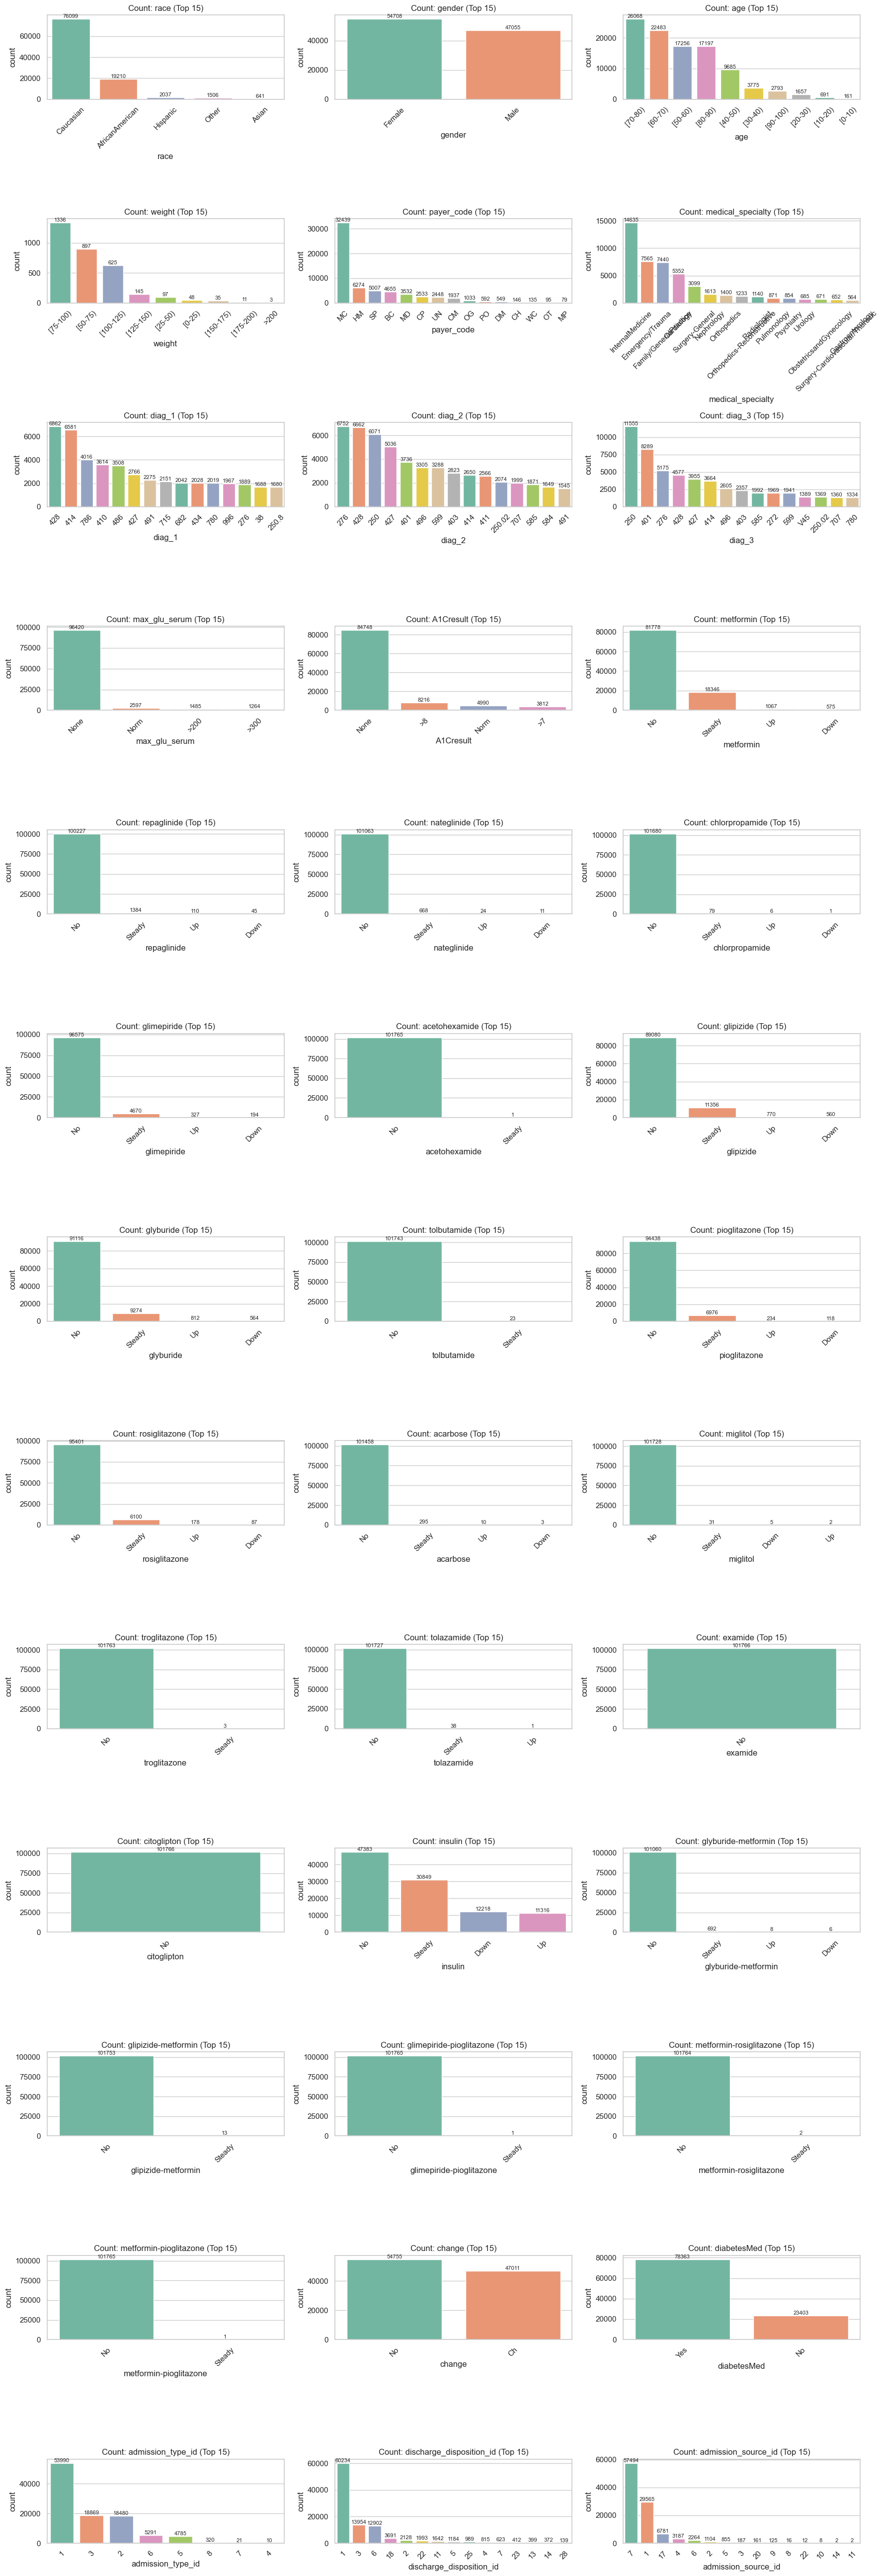

In [8]:
# Plot ALL Categorical features
# Note: For high cardinality features like diagnoses (diag_1, diag_2, diag_3), we only plot the top 15 categories to keep it readable.
cat_cols_count = len(categorical_cols)
rows = math.ceil(cat_cols_count / 3)
fig, axes = plt.subplots(rows, 3, figsize=(18, rows * 4))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    # Get top 15 categories if there are too many unique values
    top_cats = df[col].value_counts().nlargest(15).index
    sns.countplot(data=df[df[col].isin(top_cats)], x=col, ax=axes[i], palette='Set2', order=top_cats)
    for c in axes[i].containers: axes[i].bar_label(c, fmt='%.0f', fontsize=8)
    axes[i].set_title(f'Count: {col} (Top 15)')
    axes[i].tick_params(axis='x', rotation=45)

# Hide any empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(f'{plots_dir}/EDA/univariate_categorical.png', bbox_inches='tight')
plt.show()



### What we learned (Categorical Distributions)
- **Extreme Medication Imbalance (Near-Zero Variance):** Dozens of specific medication features (e.g., `chlorpropamide`, `tolbutamide`, `acetohexamide`, `glimepiride-pioglitazone`) are heavily skewed where >99% of patients have "No" (never prescribed).
- **High Cardinality ICD-9 Diagnoses:** The diagnosis columns (`diag_1`, `diag_2`, `diag_3`) contain over 700 distinct clinical ICD-9 codes, creating severe feature sparsity if left unaggregated.
- **Provider Specialty Fragmentation:** `medical_specialty` has over 70 unique values with a long tail of rare specialties having fewer than 10 patients, risking model overfitting.

### What we will do about it
- **Prune Near-Zero Variance Medications:** Drop medications where >99% of entries are "No" to eliminate noise and save dimensionality.
- **Group ICD-9 Diagnosis Codes:** Map the 700+ raw codes into broad clinical categories (e.g., Circulatory, Respiratory, Digestive, Diabetes) based on standard epidemiological grouping.
- **Group Rare Specialties:** Retain the Top 10 high-frequency specialties and aggregate all remaining rare providers into an `"Other"` category.


## 6. Feature vs Target (Readmission Risk)
We analyze how **ALL** features correlate with the 3 target classes using stacked bar charts.


### Categorical Features vs Target



--- Categorical Features Ranked by Cramér's V (Association with Target) ---


,Feature,Chi2,p-value,Cramers_V
6,diag_1,4966.473536,0.000000e+00,0.156226
7,diag_2,3969.051778,2.970695e-223,0.139892
8,diag_3,3781.584269,4.000059e-182,0.137271
37,discharge_disposition_id,3587.291304,0.000000e+00,0.132760
5,medical_specialty,1218.767114,1.840428e-170,0.108445
38,admission_source_id,1150.971841,2.317985e-221,0.075200
3,weight,27.426148,3.698274e-02,0.065493
4,payer_code,507.430868,6.135414e-87,0.064224
35,diabetesMed,386.510884,1.175514e-84,0.061628
28,insulin,516.695761,2.126586e-108,0.050385


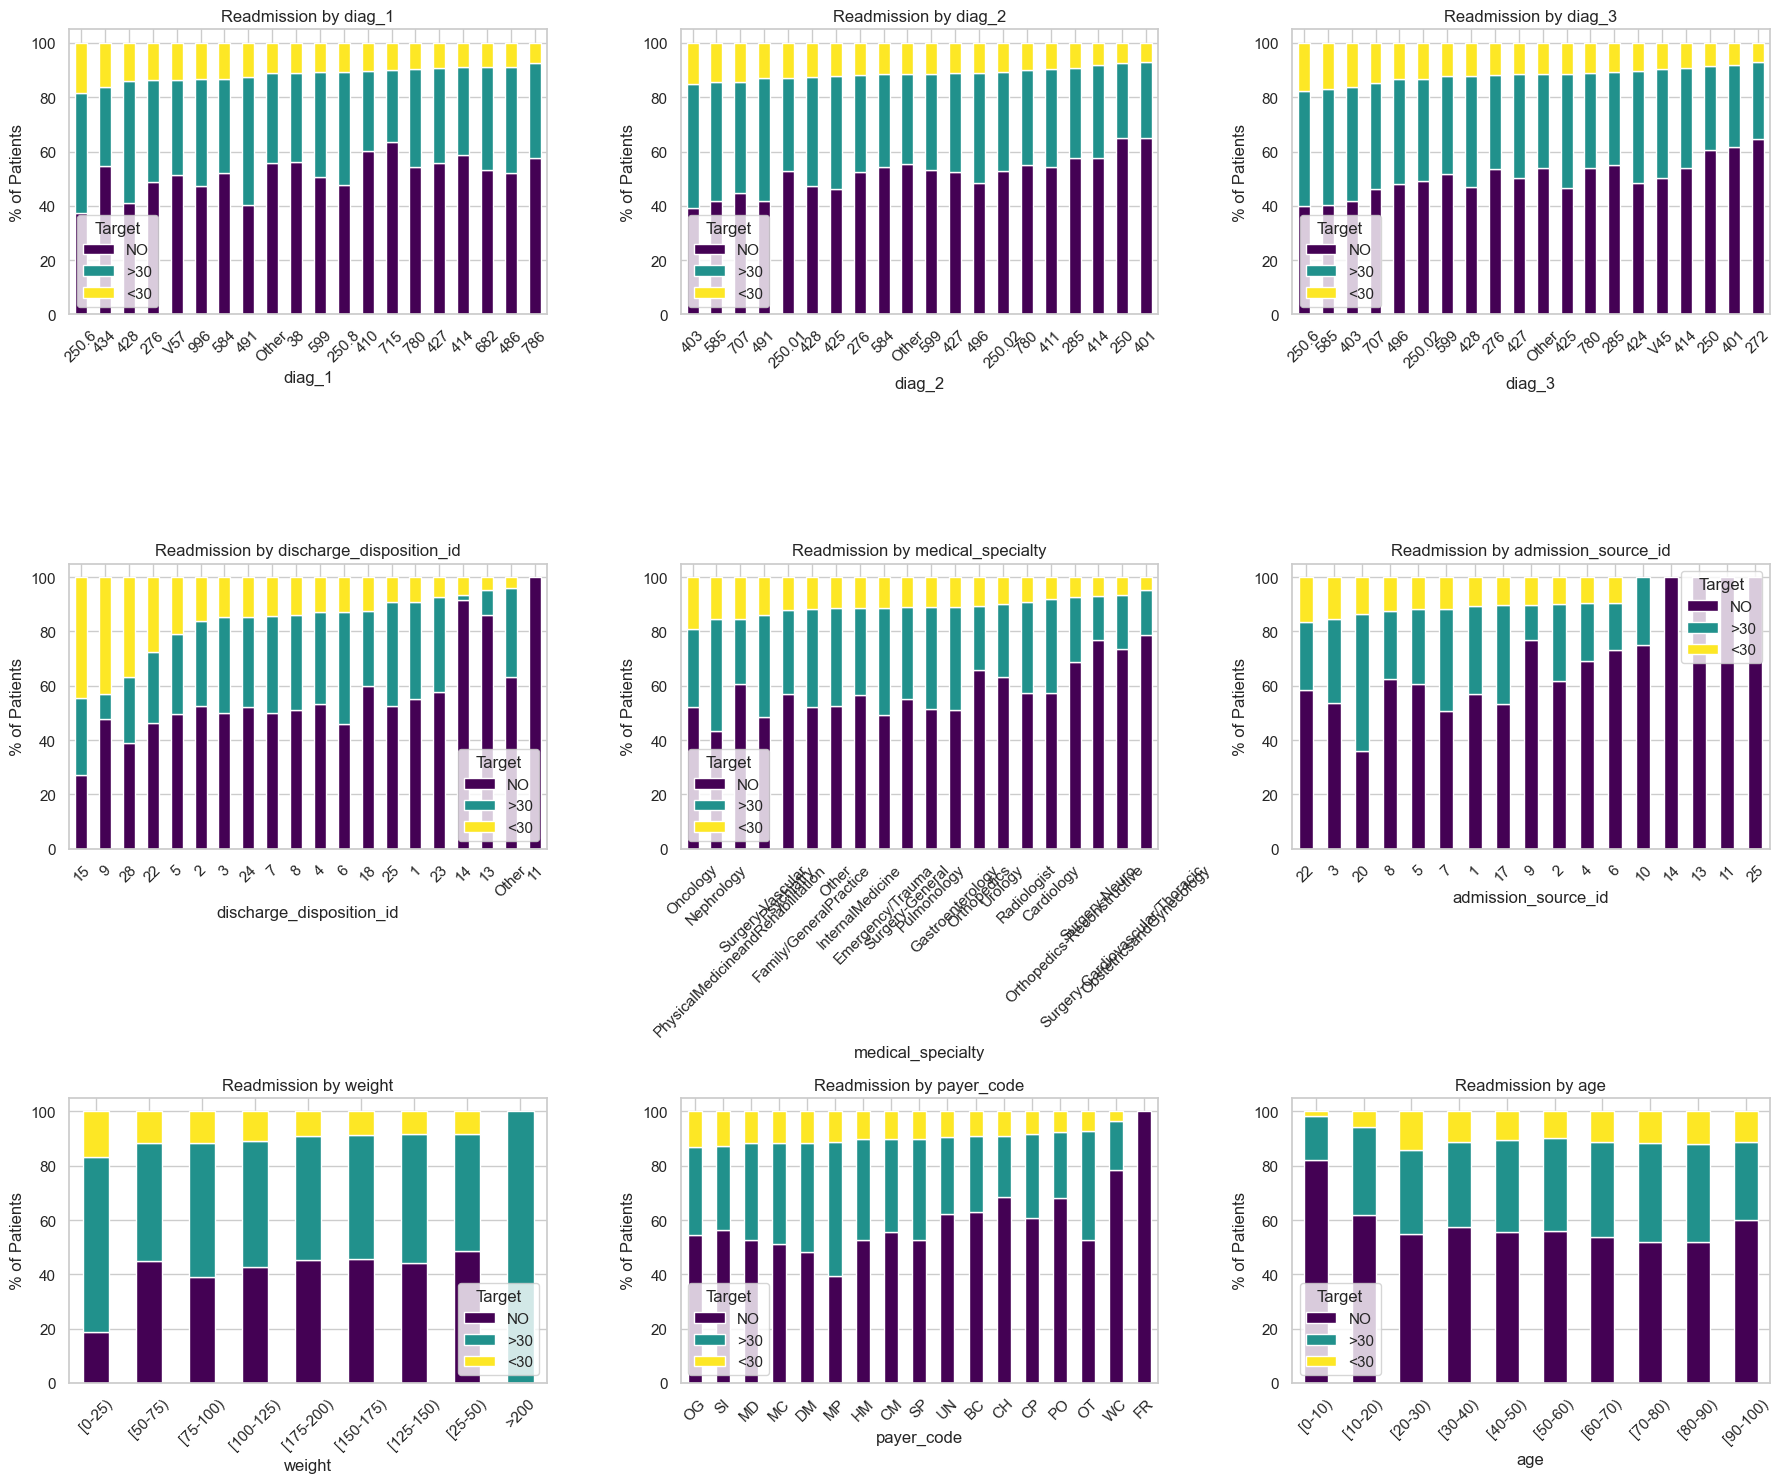


--- Categorical Feature vs Target (<30 Days Risk Tables) ---


,diag_1,<30 Risk %
0,250.6,18.51
1,434,16.22
2,428,14.11
3,276,13.61
4,V57,13.50


,diag_2,<30 Risk %
0,403,15.20
1,585,14.54
2,707,14.26
3,491,13.01
4,250.01,12.87


,diag_3,<30 Risk %
0,250.6,17.78
1,585,16.87
2,403,16.33
3,707,14.85
4,496,13.44


,discharge_disposition_id,<30 Risk %
0,15,44.44
1,9,42.86
2,28,36.69
3,22,27.70
4,5,20.86


,medical_specialty,<30 Risk %
0,Oncology,18.97
1,Nephrology,15.38
2,PhysicalMedicineandRehabilitation,15.35
3,Surgery-Vascular,13.88
4,Psychiatry,12.18


,admission_source_id,<30 Risk %
0,22,16.67
1,3,15.51
2,20,13.66
3,8,12.50
4,5,11.81


,weight,<30 Risk %
0,[0-25),16.67
1,[50-75),11.71
2,[75-100),11.45
3,[100-125),10.72
4,[175-200),9.09


,payer_code,<30 Risk %
0,OG,13.17
1,SI,12.73
2,MD,11.78
3,MC,11.75
4,DM,11.66


,age,<30 Risk %
0,[0-10),1.86
1,[10-20),5.79
2,[20-30),14.24
3,[30-40),11.23
4,[40-50),10.60


In [9]:

def plot_readmission_distribution(col, ax):
    if col not in df.columns or df[col].nunique() == 0:
        return None
    ct = pd.crosstab(df[col], df['target'], normalize='index') * 100
    if '<30' in ct.columns:
        ct = ct.sort_values(by='<30', ascending=False)
    cols = [c for c in ['NO', '>30', '<30'] if c in ct.columns]
    ct[cols].plot(kind='bar', stacked=True, ax=ax, colormap='viridis')
    ax.set_title(f'Readmission by {col}')
    ax.set_ylabel('% of Patients')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title='Target')
    return ct

# 1. Compute Chi-Square and Cramer's V for all categorical features
chi2_results = []
for col in categorical_cols:
    contingency = pd.crosstab(df[col], df['target'])
    chi2, p, dof, ex = stats.chi2_contingency(contingency)
    n = contingency.sum().sum()
    min_dim = min(contingency.shape) - 1
    cramer_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else 0
    chi2_results.append({'Feature': col, 'Chi2': chi2, 'p-value': p, 'Cramers_V': cramer_v})

chi2_df = pd.DataFrame(chi2_results).sort_values(by='Cramers_V', ascending=False)
print("\n--- Categorical Features Ranked by Cramér's V (Association with Target) ---")
display(chi2_df.head(15))

# Plot top 9 most associated features based on Cramer's V
top_features = chi2_df['Feature'].head(9).tolist()
if 'age' not in top_features:
    top_features[-1] = 'age' # Ensure age is included to demonstrate correct sorting

fig, axes = plt.subplots(3, 3, figsize=(18, 15))
axes = axes.flatten()

cat_tables = {}
for i, col in enumerate(top_features):
    ax = axes[i]
    
    # If a feature has massive cardinality (e.g., diag codes), group the tail for plotting only
    plot_col = df[col]
    if plot_col.nunique() > 20:
        top_cats = plot_col.value_counts().nlargest(19).index
        plot_col = plot_col.apply(lambda x: x if x in top_cats else 'Other')
        
    ct = pd.crosstab(plot_col, df['target'], normalize='index') * 100
    
    # Sort by risk, EXCEPT for age which must be in natural order
    if col == 'age':
        ct = ct.sort_index()
    elif '<30' in ct.columns:
        ct = ct.sort_values(by='<30', ascending=False)
        
    ct[['NO', '>30', '<30']].plot(kind='bar', stacked=True, ax=ax, colormap='viridis')
    ax.set_title(f'Readmission by {col}')
    ax.set_ylabel('% of Patients')
    ax.tick_params(axis='x', rotation=45)
    ax.legend(title='Target')
    
    cat_tables[col] = ct

plt.tight_layout()
plt.savefig(f'{plots_dir}/EDA/feature_vs_target_categorical.png', bbox_inches='tight')
plt.show()

print("\n--- Categorical Feature vs Target (<30 Days Risk Tables) ---")
for col, ct in cat_tables.items():
    if '<30' in ct.columns:
        display(pd.DataFrame({f'{col}': ct.index[:5], '<30 Risk %': ct['<30'].values[:5].round(2)}))



### Numerical Features vs Target


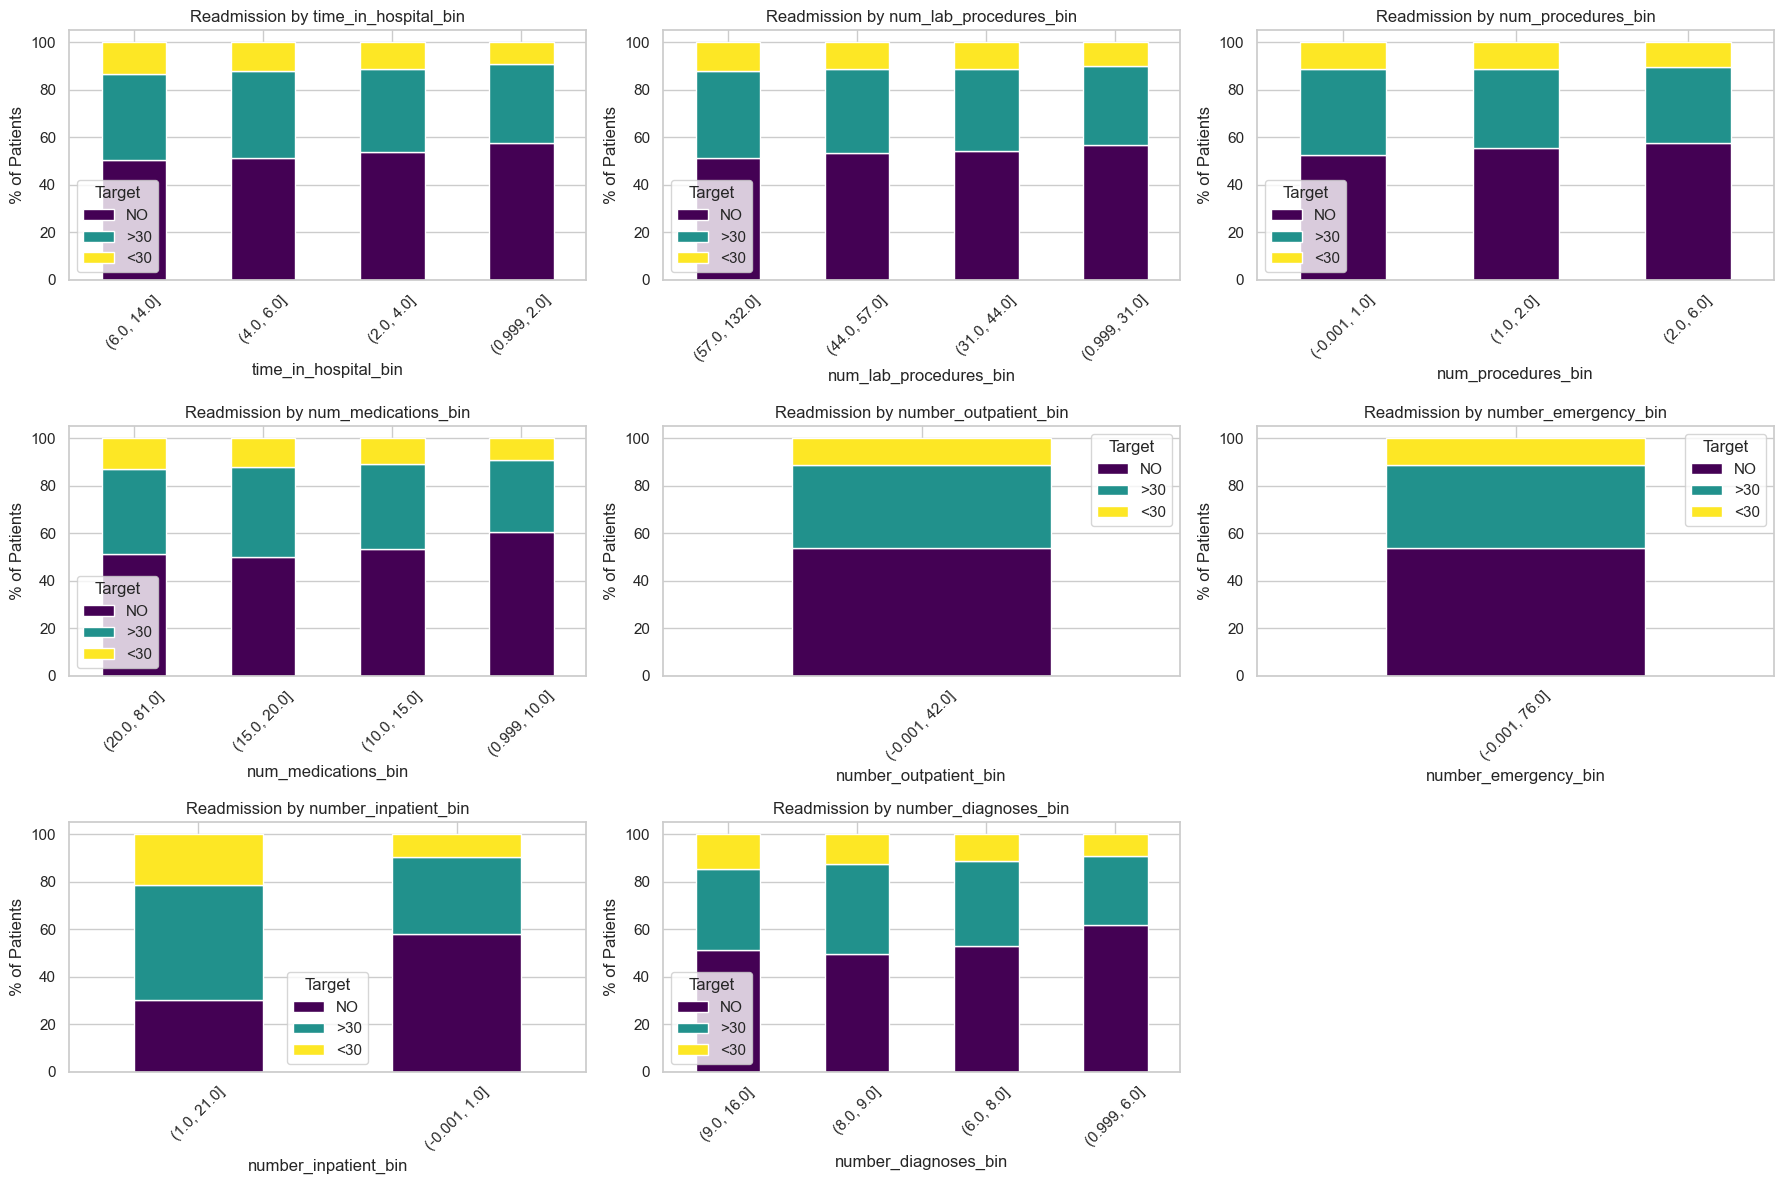


--- Numerical Feature vs Target (<30 Days Risk Tables) ---


,time_in_hospital_bin Bins (Highest Risk First),<30 Risk %
0,"(6.0, 14.0]",13.23
1,"(4.0, 6.0]",12.27
2,"(2.0, 4.0]",11.17
3,"(0.999, 2.0]",9.14


,num_lab_procedures_bin Bins (Highest Risk First),<30 Risk %
0,"(57.0, 132.0]",11.90
1,"(44.0, 57.0]",11.43
2,"(31.0, 44.0]",11.19
3,"(0.999, 31.0]",10.16


,num_procedures_bin Bins (Highest Risk First),<30 Risk %
0,"(-0.001, 1.0]",11.43
1,"(1.0, 2.0]",11.18
2,"(2.0, 6.0]",10.32


,num_medications_bin Bins (Highest Risk First),<30 Risk %
0,"(20.0, 81.0]",12.78
1,"(15.0, 20.0]",12.17
2,"(10.0, 15.0]",10.91
3,"(0.999, 10.0]",9.06


,number_outpatient_bin Bins (Highest Risk First),<30 Risk %
0,"(-0.001, 42.0]",11.16


,number_emergency_bin Bins (Highest Risk First),<30 Risk %
0,"(-0.001, 76.0]",11.16


,number_inpatient_bin Bins (Highest Risk First),<30 Risk %
0,"(1.0, 21.0]",21.40
1,"(-0.001, 1.0]",9.44


,number_diagnoses_bin Bins (Highest Risk First),<30 Risk %
0,"(9.0, 16.0]",14.78
1,"(8.0, 9.0]",12.38
2,"(6.0, 8.0]",11.30
3,"(0.999, 6.0]",9.12


In [10]:
# Plot for ALL numerical features (by binning them)
num_rows = math.ceil(num_cols_count / 3)
fig, axes = plt.subplots(num_rows, 3, figsize=(18, num_rows * 4))
axes = axes.flatten()

num_tables = {}
for i, col in enumerate(numeric_cols):
    # Create 4 quantile bins for the numerical feature
    bin_col = f'{col}_bin'
    try:
        df[bin_col] = pd.qcut(df[col], q=4, duplicates='drop')
        ct = plot_readmission_distribution(bin_col, axes[i])
        if ct is not None:
            num_tables[bin_col] = ct
    except ValueError:
        # If qcut fails (e.g. too many zeros), use regular cut
        df[bin_col] = pd.cut(df[col], bins=4)
        ct = plot_readmission_distribution(bin_col, axes[i])
        if ct is not None:
            num_tables[bin_col] = ct

# Hide any empty subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(f'{plots_dir}/EDA/feature_vs_target_numerical.png', bbox_inches='tight')
plt.show()

print("\n--- Numerical Feature vs Target (<30 Days Risk Tables) ---")
for col, ct in num_tables.items():
    if '<30' in ct.columns:
        display(pd.DataFrame({f'{col} Bins (Highest Risk First)': ct.index[:4].astype(str), '<30 Risk %': ct['<30'].values[:4].round(2)}))


# Clean up temporary bin columns so df stays pristine
df.drop(columns=[f'{col}_bin' for col in numeric_cols if f'{col}_bin' in df.columns], inplace=True)


### What we learned
- Across almost all features, the proportion of `<30` and `>30` fluctuates.
- Certain `discharge_disposition_id` codes have very high readmission rates.
- Patients with higher `number_inpatient` (previous inpatient visits) have noticeably higher proportions of early readmission (`<30`).
- Medication changes (`change` = "Ch") slightly increase the likelihood of readmission.

### What we will do about it
- `number_inpatient` will likely be a very strong predictive feature.
- We will group similar discharge disposition codes and admission source codes to strengthen the signal for the models.



## 7. Feature Relationships
Checking for multicollinearity amongst ALL numerical features.


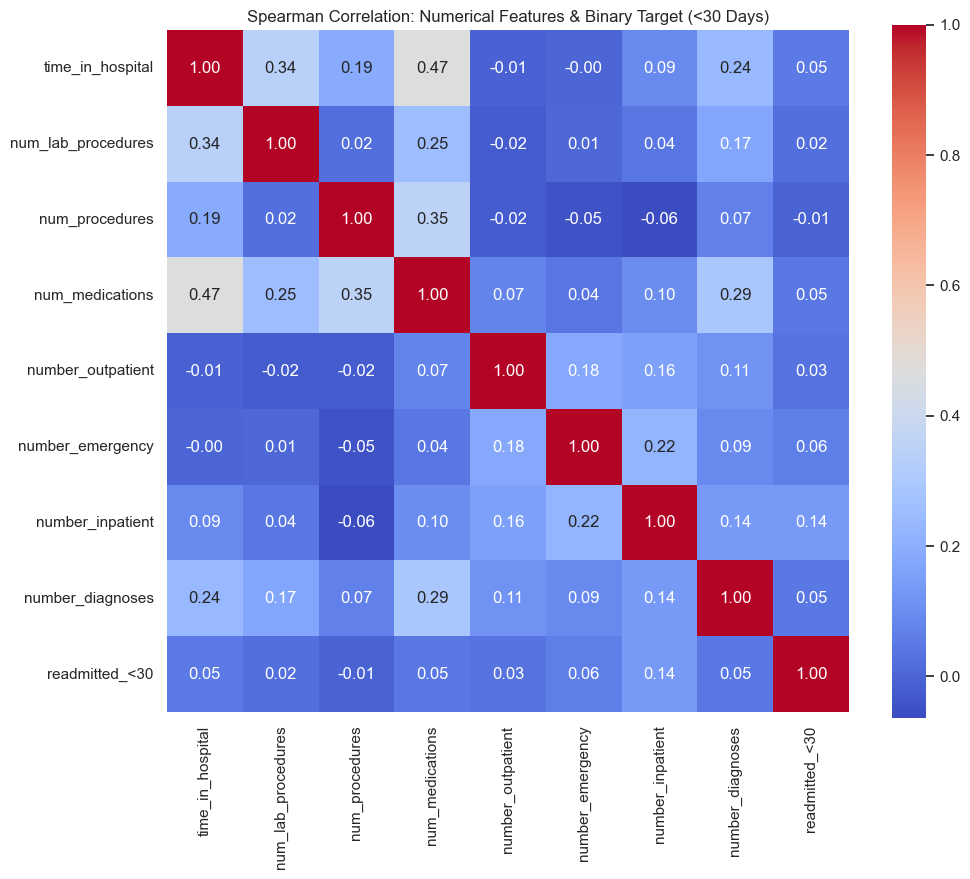


--- Numerical Feature Correlation with Binary Target (<30 Days) ---
                    Spearman_r
number_inpatient      0.138382
number_emergency      0.063438
time_in_hospital      0.050904
number_diagnoses      0.047230
num_medications       0.045423
number_outpatient     0.034169
num_lab_procedures    0.020564
num_procedures       -0.006113


In [11]:
# Spearman Correlation: Numerical Features & Target Correlation Check
# Binary target indicator: 1 = early readmission (<30 days), 0 = no / late readmission
target_binary = (df['readmitted'] == '<30').astype(int)
num_with_target = df[numeric_cols].copy()
num_with_target['readmitted_<30'] = target_binary

corr_full = num_with_target.corr(method='spearman')

# Plot heatmap showing inter-feature multicollinearity AND correlation with target
plt.figure(figsize=(11, 9))
sns.heatmap(corr_full, annot=True, fmt=".2f", cmap='coolwarm', cbar=True, square=True)
plt.title('Spearman Correlation: Numerical Features & Binary Target (<30 Days)')
plt.savefig(f'{plots_dir}/EDA/correlation_heatmap.png', bbox_inches='tight')
plt.show()

# Ranked feature correlation with target
target_corr = corr_full['readmitted_<30'].drop('readmitted_<30').sort_values(ascending=False)
print("\n--- Numerical Feature Correlation with Binary Target (<30 Days) ---")
print(pd.DataFrame({'Spearman_r': target_corr}))


### What we learned (Feature Relationships & Target Correlation)
- **Multicollinearity:** `num_medications` and `time_in_hospital` are moderately correlated ($r = 0.47$), followed by `num_medications` and `num_procedures` ($r = 0.39$). No extreme collinearity ($r > 0.80$) exists between numerical features.
- **Target Association:** `number_inpatient` exhibits the highest positive monotonic rank correlation with early readmission ($<30$), confirming that prior hospital utilization is the leading numeric predictor.

### What we will do about it
- All core numerical features can be retained for tree-based models without risk of severe collinearity breakdown.
- We will engineer combined utilization signals (e.g., `total_visits = inpatient + emergency + outpatient`) in Phase 4 to aggregate the historical healthcare burden.


## 8. Data Quality & Conceptual Leakage
Certain patients (e.g., deceased or transferred to hospice) conceptually cannot be readmitted. Including them can bias the model.


In [12]:
# Check discharge_disposition_id for expired/hospice patients
# Codes 11, 13, 14, 19, 20, 21 represent death or hospice
terminal_codes = [11, 13, 14, 19, 20, 21]
terminal_patients = df[df['discharge_disposition_id'].isin(terminal_codes)]

print(f"Patients discharged to hospice or expired: {len(terminal_patients)}")



Patients discharged to hospice or expired: 2423


### What we learned
- Thousands of patients were discharged to hospice or expired.
- These patients are virtually guaranteed not to be readmitted, meaning they are "easy" negatives that artificially inflate model performance for the 'NO' class.

### What we will do about it
- We will **drop** all rows with these discharge disposition codes during preprocessing to ensure the model focuses on patients who actually *could* be readmitted.



## 9. Targeted EDA (Before Preprocessing)
We need to explicitly analyze the ID mappings and the internal distributions of test results and medications before we can safely finalize Phase 4 and Phase 5.


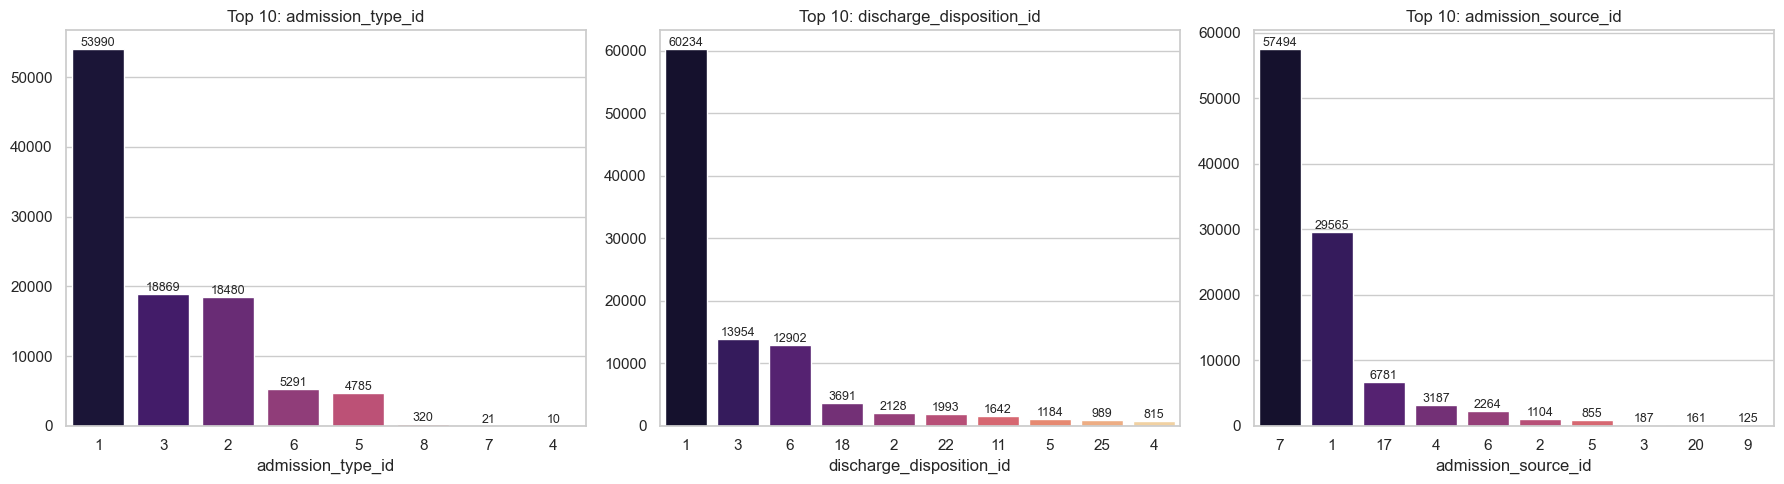

In [13]:
# A. ID Codes Distributions
id_cols_to_check = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(id_cols_to_check):
    counts = df[col].value_counts().nlargest(10)
    sns.barplot(x=counts.index, y=counts.values, ax=axes[i], order=counts.index, palette='magma')
    for c in axes[i].containers: axes[i].bar_label(c, fmt='%.0f', fontsize=9)
    axes[i].set_title(f'Top 10: {col}')
    
plt.tight_layout()
plt.savefig(f'{plots_dir}/EDA/id_mappings_targeted.png', bbox_inches='tight')
plt.show()



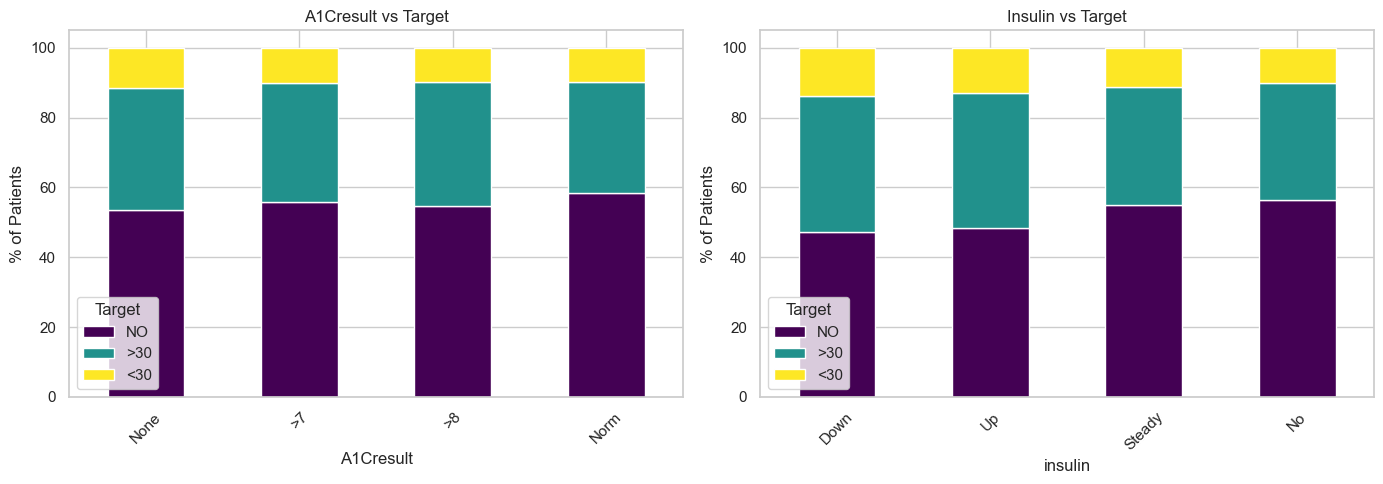

In [14]:
# B. Test Results & Medications Ordinality Check
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A1Cresult vs Readmission
plot_readmission_distribution('A1Cresult', axes[0])
axes[0].set_title("A1Cresult vs Target")

# Plot Insulin (since it's the most common) vs Readmission
plot_readmission_distribution('insulin', axes[1])
axes[1].set_title("Insulin vs Target")

plt.tight_layout()
plt.savefig(f'{plots_dir}/EDA/meds_tests_targeted.png', bbox_inches='tight')
plt.show()



### What we learned from Targeted EDA
- For `A1Cresult`, the proportion of early readmissions (`<30`) does **not** strictly increase from `Norm` -> `>7` -> `>8`. This means it is NOT strictly ordinal in relation to our target.
- For `insulin`, the `Up` and `Down` categories exhibit different risk profiles compared to `Steady`.
- ID columns are heavily concentrated in just 2-4 categories (e.g., ID 1, 2, 3), meaning we can safely group the long tail into "Other".

### What we will do about it
- We will group the ID columns based on their Top 3 mapped categories and map the rest to "Other" in Phase 4.
- We will use **One-Hot Encoding** (Nominal) for `A1Cresult` and medications in Phase 5 rather than Ordinal Encoding, as it prevents forcing false linear assumptions on non-linear risks.



## 10. EDA Conclusions & Next Steps
We have a clear path forward for the Preprocessing phase.

| Finding | Implication | Action |
| :--- | :--- | :--- |
| `weight` has 97% missing data | Unusable feature | Drop column |
| Near-zero variance on many medications | No predictive power | Drop columns with >99% 'No' |
| Multi-class imbalance | Accuracy is a bad metric | Use SMOTE/class weights |
| High encounters per patient | Random split causes leakage | GroupKFold / Split by `patient_nbr` |
| Hospice/Death discharge codes | Inflates negative classes | Drop rows with terminal codes |
| Diagnosis codes have 700+ unique values | High dimensionality | Group ICD-9 codes by category |
| Tests/Meds lack strict monotonic correlation | Ordinal encoding creates false math | Use One-Hot Encoding |

